## Machine Learning-Based Training Intelligence

Marathon training prescription has traditionally relied on generalised protocols that fail to account for the substantial inter-individual variability in physiological response, recovery capacity, and cumulative load tolerance. Static plans ignore the athlete's evolving state — a runner who slept poorly, accumulated fatigue over several weeks, or recently recovered from illness will respond very differently to the same prescribed session than the same runner at peak readiness.

Translating historical performance data into actionable, personalised guidance requires methods that can operate on the temporal structure of training rather than simple aggregate statistics. Time series of distance, heart rate, and perceived effort carry rich sequential structure: trends, cycles, anomalies, and regime shifts that aggregate statistics obscure. Extracting useful signals from this structure is precisely the domain where machine learning — and in particular deep learning — provides the most leverage.

This notebook applies, and will continue to extend, a suite of data-driven techniques to bridge the gap between raw training logs and intelligent, individualised recommendations.

**Current implementations:**
- **Acute:Chronic Workload Ratio (ACWR):** A signal-processing approach that monitors the balance between short-term training load and established fitness baseline, providing real-time injury risk estimation directly from activity data.
- **Race Time Predictor:** A linear regression model that maps peak training week volume to marathon finish time, establishing a baseline pipeline extensible to richer feature sets as race history grows.

In [1]:
import numpy as np
import pandas as pd
import os
from sqlalchemy import create_engine
from dotenv import load_dotenv
load_dotenv()

host     = os.getenv("SUPABASE_HOST")
user_db  = os.getenv("SUPABASE_USER")
password = os.getenv("SUPABASE_PASSWORD")
engine   = create_engine(f"postgresql+psycopg2://{user_db}:{password}@{host}:6543/postgres")

df_ml = pd.read_sql("""
    SELECT a.start_date, a.activity_type, a.activity_name,
           a.distance, a.duration, a.elevation,
           a.avg_speed, a.avg_heartrate, a.suffer_score
    FROM activities a
    JOIN athletes ath ON a.athlete_id = ath.id
    ORDER BY a.start_date ASC
""", engine)
df_ml["start_date"] = pd.to_datetime(df_ml["start_date"])
runs_ml = df_ml[df_ml["activity_type"] == "Run"].dropna(subset=["distance"]).copy()

## 1. Acute:Chronic Workload Ratio (ACWR) — Injury Risk Monitor

The ACWR is a well-validated sports science metric that quantifies training load balance by comparing recent stress against established fitness. It is defined as:

**ACWR = Acute Load (7-day sum) ÷ Chronic Load (rolling 28-day weekly average)**

The chronic load acts as a proxy for the athlete's current fitness and load-bearing capacity — the accumulated conditioning that determines what the body can absorb. The acute load captures the most recent stress imposed. Their ratio is sensitive to both sudden spikes (a 40 km week after four weeks of 20 km) and gradual under-recovery, making it a compact but powerful signal of training state.

**Risk zones:**
- **< 0.8:** Under-training — insufficient stimulus to maintain or build fitness; fitness will erode.
- **0.8 – 1.3:** Sweet spot — sufficient stimulus for adaptation without elevated injury risk.
- **1.3 – 1.5:** Caution — the athlete has ramped up significantly relative to baseline; monitor closely.
- **> 1.5:** High risk — load is well above what the body is conditioned to absorb; back off immediately.

These thresholds are derived from population-level research across team sports and endurance athletes. However, individual athletes differ substantially in their habitual load ranges and resilience. To account for this, the chart overlays **personalised thresholds** computed from percentile distributions (p25, p75, p90) of the athlete's own ACWR history during active training periods — capturing what is *normal* for this individual specifically, rather than applying generic cutoffs.

From a machine learning perspective, ACWR is a candidate input feature for the sequence models planned in future iterations of this notebook. As a compressed, time-varying signal of load balance, it captures complementary information to raw distance and heart-rate series — summarising the *relationship* between recent and historical load in a single scalar that a recurrent model can condition on when generating recommendations.

C:\Users\persif\AppData\Local\Temp\ipykernel_12808\2294249794.py:7: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  BASELINE_START = DISPLAY_START - pd.Timedelta(weeks=4)   # 4-week warm-up for chronic baseline


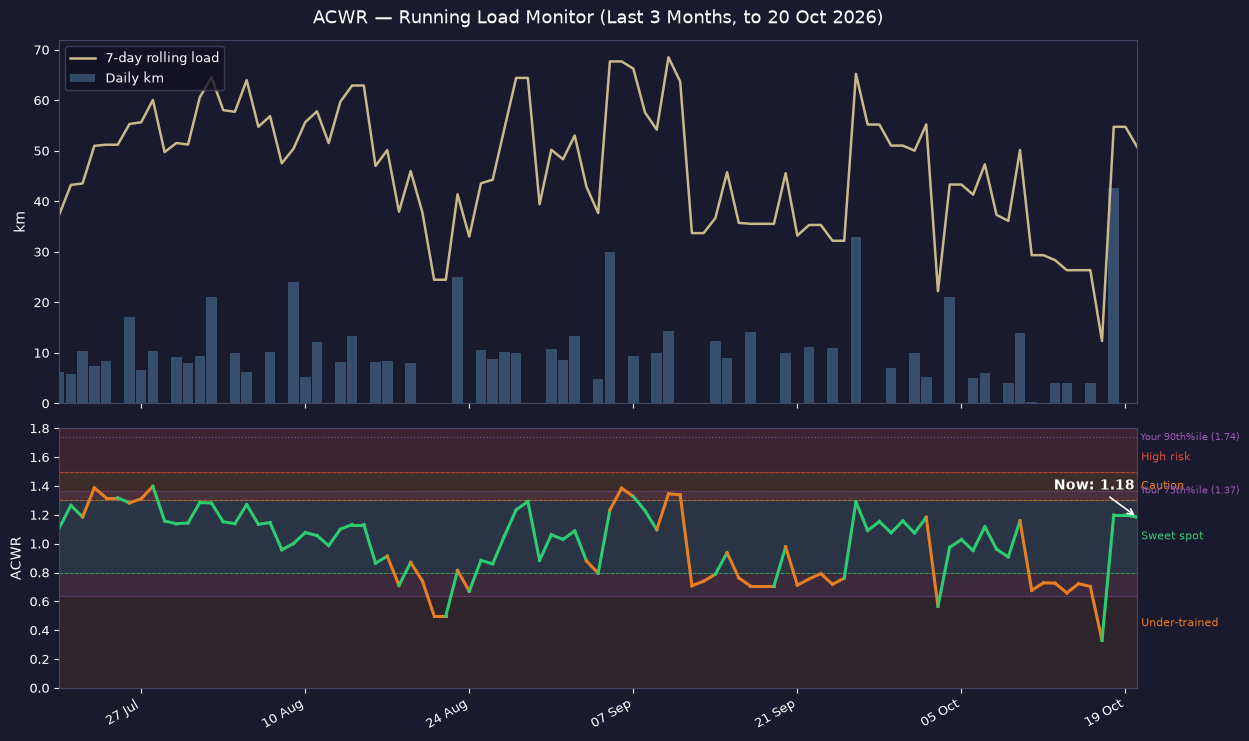

Acute load  (last 7 days):     50.7 km
Chronic load (avg weekly/28d): 42.9 km
Current ACWR:                  1.184  →  sweet spot ✓

Personalised thresholds (full training history, active periods only):
  Typical range  p25–p75 : 0.64 – 1.37
  Elevated       p90     : 1.74


In [2]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker

today          = pd.Timestamp.today().normalize()
DISPLAY_START  = today - pd.DateOffset(months=3)
BASELINE_START = DISPLAY_START - pd.Timedelta(weeks=4)   # 4-week warm-up for chronic baseline

# ── Build daily load from baseline (for rolling windows) ─────────────────────
baseline = runs_ml[runs_ml["start_date"] >= BASELINE_START].copy()
baseline["date"] = baseline["start_date"].dt.normalize()

daily = baseline.groupby("date")["distance"].sum().rename("km")
idx_full = pd.date_range(BASELINE_START, today, freq="D")
daily = daily.reindex(idx_full, fill_value=0.0)

acute   = daily.rolling(7,  min_periods=1).sum()
chronic = daily.rolling(28, min_periods=7).sum() / 4
acwr    = (acute / chronic).replace([np.inf, -np.inf], np.nan)

current_acwr    = acwr.dropna().iloc[-1] if acwr.dropna().size else np.nan
current_acute   = acute.iloc[-1]
current_chronic = chronic.iloc[-1]

# ── Personalised thresholds from full training history ────────────────────────
full_daily = (runs_ml.assign(date=runs_ml["start_date"].dt.normalize())
              .groupby("date")["distance"].sum().rename("km"))
full_idx = pd.date_range(runs_ml["start_date"].min().normalize(), today, freq="D")
full_daily = full_daily.reindex(full_idx, fill_value=0.0)

acute_hist   = full_daily.rolling(7,  min_periods=1).sum()
chronic_hist = full_daily.rolling(28, min_periods=7).sum() / 4
acwr_hist    = (acute_hist / chronic_hist).replace([np.inf, -np.inf], np.nan)
acwr_active  = acwr_hist[chronic_hist > 5].dropna()   # active training periods only

personal_lo  = float(np.percentile(acwr_active, 25))
personal_hi  = float(np.percentile(acwr_active, 75))
personal_top = float(np.percentile(acwr_active, 90))

# ── Trim to display window (last 3 months) ────────────────────────────────────
plot_mask  = daily.index >= DISPLAY_START
dates      = daily.index[plot_mask]
daily_plot = daily.values[plot_mask]
acute_plot = acute.values[plot_mask]
acwr_vals  = acwr.values[plot_mask]

# ── Plot ─────────────────────────────────────────────────────────────────────
BG      = "#1A1A2E"
CREAM   = "#C8B98A"
ACUTE_C = "#5B8DB8"
RISK_G  = "#2ECC71"
RISK_O  = "#E67E22"
RISK_R  = "#E74C3C"
RISK_P  = "#9B59B6"   # purple — personalised thresholds

fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(14, 8), facecolor=BG,
    gridspec_kw={"height_ratios": [1.4, 1], "hspace": 0.08}
)
for ax in (ax_top, ax_bot):
    ax.set_facecolor(BG)
    ax.tick_params(colors="white", labelsize=9)
    for spine in ax.spines.values():
        spine.set_edgecolor("#444466")

# — top: daily bars + acute load line —
ax_top.bar(dates, daily_plot, color=ACUTE_C, alpha=0.45, width=0.9, label="Daily km")
ax_top.plot(dates, acute_plot, color=CREAM, linewidth=1.8, label="7-day rolling load")
ax_top.set_xlim(dates[0], dates[-1])
ax_top.set_ylabel("km", color="white", fontsize=10)
ax_top.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax_top.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0, interval=2))
plt.setp(ax_top.get_xticklabels(), visible=False)
ax_top.legend(facecolor="#111122", edgecolor="#444466", labelcolor="white",
              fontsize=9, loc="upper left")
ax_top.set_title(f"ACWR — Running Load Monitor (Last 3 Months, to {today.strftime('%d %b %Y')})",
                 color="white", fontsize=13, pad=12)

# — bottom: ACWR line + coloured risk bands —
ax_bot.axhspan(0.8, 1.3, color=RISK_G, alpha=0.12, zorder=0)
ax_bot.axhspan(1.3, 1.5, color=RISK_O, alpha=0.18, zorder=0)
ax_bot.axhspan(1.5, 3.0, color=RISK_R, alpha=0.18, zorder=0)
ax_bot.axhspan(0.0, 0.8, color=RISK_O, alpha=0.10, zorder=0)

ax_bot.axhline(0.8, color=RISK_G, linewidth=0.7, linestyle="--", alpha=0.6)
ax_bot.axhline(1.3, color=RISK_O, linewidth=0.7, linestyle="--", alpha=0.6)
ax_bot.axhline(1.5, color=RISK_R, linewidth=0.7, linestyle="--", alpha=0.6)

# — personalised band (p25–p75) and p90 elevated marker —
ax_bot.axhspan(personal_lo, personal_hi, color=RISK_P, alpha=0.12, zorder=0)
ax_bot.axhline(personal_lo,  color=RISK_P, linewidth=0.7, linestyle=":", alpha=0.7)
ax_bot.axhline(personal_hi,  color=RISK_P, linewidth=0.7, linestyle=":", alpha=0.7)
ax_bot.axhline(personal_top, color=RISK_P, linewidth=0.9, linestyle=":", alpha=0.7)

for y, label, col in [(1.05, "Sweet spot", RISK_G), (1.4, "Caution", RISK_O),
                       (1.6, "High risk", RISK_R), (0.45, "Under-trained", RISK_O)]:
    ax_bot.text(dates[-1], y, f" {label}", color=col, fontsize=8,
                va="center", ha="left", clip_on=False)

ax_bot.text(dates[-1], personal_hi,  f" Your 75th%ile ({personal_hi:.2f})",
            color=RISK_P, fontsize=7.5, va="center", ha="left", clip_on=False)
ax_bot.text(dates[-1], personal_top, f" Your 90th%ile ({personal_top:.2f})",
            color=RISK_P, fontsize=7.5, va="center", ha="left", clip_on=False)

# colour the ACWR line by zone
for i in range(1, len(dates)):
    v = acwr_vals[i]
    if np.isnan(v):
        continue
    c = RISK_G if 0.8 <= v <= 1.3 else (RISK_O if v <= 1.5 else RISK_R)
    ax_bot.plot(dates[i-1:i+1], acwr_vals[i-1:i+1], color=c, linewidth=2.2)

ax_bot.set_xlim(dates[0], dates[-1])
ax_bot.set_ylim(0, max(acwr_vals[~np.isnan(acwr_vals)].max() * 1.15, 1.8))
ax_bot.set_ylabel("ACWR", color="white", fontsize=10)
ax_bot.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax_bot.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0, interval=2))
plt.setp(ax_bot.get_xticklabels(), rotation=30, ha="right", color="white")

if not np.isnan(current_acwr):
    ax_bot.annotate(
        f"Now: {current_acwr:.2f}",
        xy=(dates[-1], current_acwr),
        xytext=(-60, 20), textcoords="offset points",
        color="white", fontsize=10, fontweight="bold",
        arrowprops=dict(arrowstyle="->", color="white", lw=1.2),
    )

fig.subplots_adjust(left=0.07, right=0.84, top=0.93, bottom=0.12)
FIGURES_DIR = os.path.join(os.getenv("FIGURES_DIR"), "MLEngine")
os.makedirs(FIGURES_DIR, exist_ok=True)
plt.savefig(os.path.join(FIGURES_DIR, "ACWR_load_monitor.png"), dpi=150,
            bbox_inches="tight", facecolor=BG)
plt.show()

# ── Summary ──────────────────────────────────────────────────────────────────
zone = ("sweet spot ✓" if 0.8 <= current_acwr <= 1.3
        else ("caution — slight spike" if current_acwr <= 1.5
              else "HIGH RISK — back off"))
print(f"Acute load  (last 7 days):     {current_acute:.1f} km")
print(f"Chronic load (avg weekly/28d): {current_chronic:.1f} km")
print(f"Current ACWR:                  {current_acwr:.3f}  →  {zone}")
print(f"\nPersonalised thresholds (full training history, active periods only):")
print(f"  Typical range  p25–p75 : {personal_lo:.2f} – {personal_hi:.2f}")
print(f"  Elevated       p90     : {personal_top:.2f}")

## 2. Race Time Predictor — Marathon Block Regression

With three completed marathon training blocks in the dataset (Eindhoven 2024, Copenhagen 2026, Amsterdam 2026), it becomes possible to ask a simple but useful question: *does the structure of a training block predict race-day performance?*

The fundamental challenge here is sample size. Three data points is the smallest dataset on which a model can be fit — leave-one-out cross-validation is mathematically possible but statistically meaningless, and any multi-feature model would perfectly interpolate noise. The responsible approach is to use a **single, well-motivated predictor**: peak training week volume (km).

**Why peak week km?** Sports science consistently identifies peak weekly load as one of the strongest individual-level predictors of marathon performance. It captures the athlete's accumulated aerobic base and the specificity of race preparation in a single number — less confounded by training block length than total volume, and more directly linked to VO₂max-adjacent adaptations than session count or long-run frequency.

**Model specification:** `finish_time ~ β₀ + β₁ × peak_week_km`

A negative slope (β₁ < 0) confirms the expected direction: higher peak load → faster finish. The model is fitted with ordinary least squares via scikit-learn and will automatically incorporate future marathon results as the dataset grows.

**Limitations:**
- n=3 renders statistical inference meaningless — no p-values, R², or confidence intervals should be taken seriously.
- No periodisation structure is captured: taper quality, long-run distribution, and aerobic efficiency differences are invisible to this model.
- This is a retrospective pattern match across one athlete's data, not a generalised predictor.

The left panel shows the relative training profile across all three blocks (each metric normalised to its own maximum), providing context for the regression on the right.

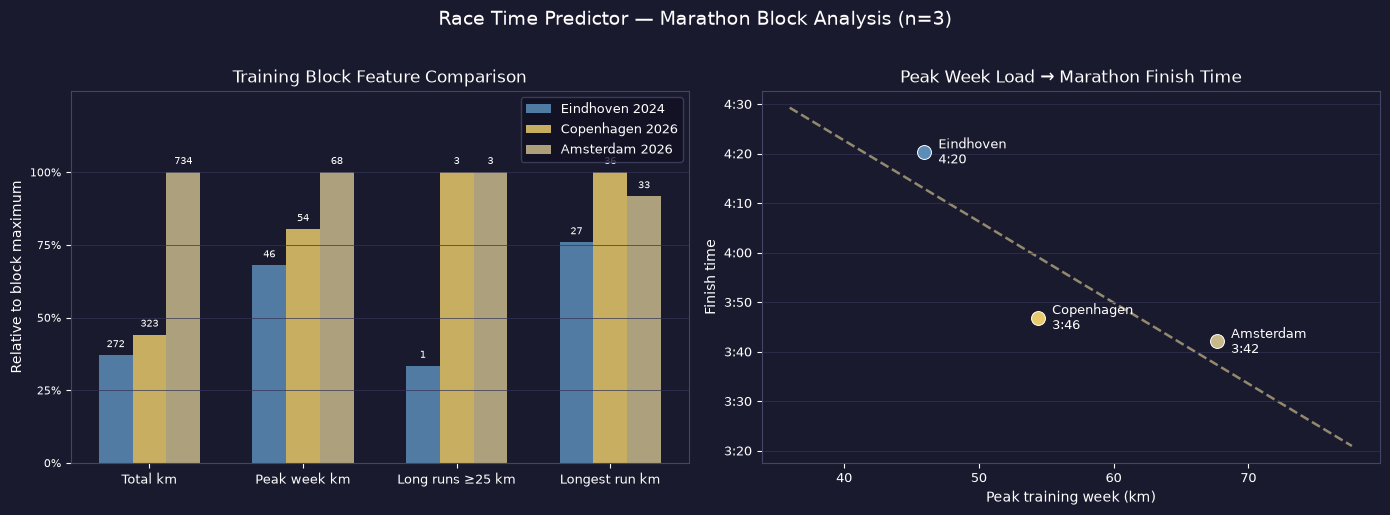

Model: finish_time = -1.64 min per km/wk peak  +  328.2 min
Higher peak week → faster finish (1.6 min per extra km/wk)
Fitted on 3 marathons — directional only.

  Eindhoven 2024          peak 46 km/wk  →  predicted 4:12  (actual 4:20)
  Copenhagen 2026         peak 54 km/wk  →  predicted 3:59  (actual 3:46)
  Amsterdam 2026          peak 68 km/wk  →  predicted 3:37  (actual 3:42)


In [7]:
from sklearn.linear_model import LinearRegression

# ── Block definitions ─────────────────────────────────────────────────────────
# race_min_override: used when the race activity is not yet in the database
BLOCKS = [
    {"name": "Eindhoven 2024",  "start": "2024-07-01", "race": "2024-10-13", "color": "#5B8DB8"},
    {"name": "Copenhagen 2026", "start": "2026-03-01", "race": "2026-05-10", "color": "#E8C96B",
     "race_min_override": 230.0},   # 3:50:00
    {"name": "Amsterdam 2026",  "start": "2026-06-15", "race": "2026-10-18", "color": "#C8B98A"},
]

def extract_features(start, race):
    race_date = pd.Timestamp(race).date()
    b = runs_ml[
        (runs_ml["start_date"] >= start) &
        (runs_ml["start_date"].dt.date < race_date)   # exclude race day itself
    ].copy()
    b["week"] = (b["start_date"] - pd.Timestamp(start)).dt.days // 7
    weekly = b.groupby("week")["distance"].sum()
    return {
        "total_km":       float(b["distance"].sum()),
        "peak_week_km":   float(weekly.max()) if not weekly.empty else np.nan,
        "n_long_runs":    int((b["distance"] >= 25).sum()),
        "longest_km":     float(b["distance"].max()) if not b.empty else np.nan,
        "training_weeks": int(b["week"].max()) + 1 if not b.empty else 0,
    }

def get_race_time(race_date):
    r = runs_ml[
        (runs_ml["start_date"].dt.date == pd.Timestamp(race_date).date()) &
        (runs_ml["distance"] >= 41)
    ]
    return float(r["duration"].iloc[0]) if not r.empty else np.nan

def fmt_time(minutes):
    h, rem = divmod(int(minutes), 60)
    return f"{h}:{rem:02d}"

records = []
for b in BLOCKS:
    race_min = get_race_time(b["race"])
    if np.isnan(race_min):
        race_min = b.get("race_min_override", np.nan)
    records.append({"name": b["name"], "color": b["color"],
                    "race_min": race_min,
                    **extract_features(b["start"], b["race"])})
df_pred = pd.DataFrame(records)

# ── Linear regression: peak_week_km → finish time ────────────────────────────
df_fit = df_pred.dropna(subset=["peak_week_km", "race_min"])
X = df_fit[["peak_week_km"]].values
y = df_fit["race_min"].values
model = LinearRegression().fit(X, y)
x_rng = np.linspace(X.min() - 10, X.max() + 10, 100)
y_rng = model.predict(x_rng.reshape(-1, 1))

# ── Plot ─────────────────────────────────────────────────────────────────────
BG    = "#1A1A2E"
CREAM = "#C8B98A"

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(14, 5), facecolor=BG)
for ax in (ax_left, ax_right):
    ax.set_facecolor(BG)
    ax.tick_params(colors="white", labelsize=9)
    for spine in ax.spines.values():
        spine.set_edgecolor("#444466")

# — left: normalised feature comparison (relative to per-feature max) —
feat_cols   = ["total_km", "peak_week_km", "n_long_runs", "longest_km"]
feat_labels = ["Total km", "Peak week km", "Long runs ≥25 km", "Longest run km"]
norm = df_pred[feat_cols].copy()
for c in feat_cols:
    m = norm[c].max()
    if m > 0:
        norm[c] /= m

n_feats = len(feat_cols)
bar_w   = 0.22
x_pos   = np.arange(n_feats)

for i, (_, row) in enumerate(df_pred.iterrows()):
    offset = (i - 1) * bar_w
    bars = ax_left.bar(x_pos + offset, [norm.iloc[i][c] for c in feat_cols],
                       bar_w, color=row["color"], alpha=0.85, label=row["name"])
    for bar, col in zip(bars, feat_cols):
        raw = df_pred.iloc[i][col]
        ax_left.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02,
                     f"{raw:.0f}", ha="center", va="bottom", color="white", fontsize=7)

ax_left.set_xticks(x_pos)
ax_left.set_xticklabels(feat_labels, color="white", fontsize=9)
ax_left.set_ylim(0, 1.28)
ax_left.set_ylabel("Relative to block maximum", color="white", fontsize=10)
ax_left.set_title("Training Block Feature Comparison", color="white", fontsize=12)
ax_left.legend(facecolor="#111122", edgecolor="#444466", labelcolor="white", fontsize=9)
ax_left.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax_left.set_yticklabels(["0%", "25%", "50%", "75%", "100%"], color="white", fontsize=8)
ax_left.yaxis.grid(True, color="#333355", linewidth=0.5, zorder=0)

# — right: regression scatter + fit line —
ax_right.plot(x_rng, y_rng, color=CREAM, linewidth=1.8, linestyle="--", alpha=0.7, zorder=1)

for _, row in df_pred.iterrows():
    if np.isnan(row["race_min"]) or np.isnan(row["peak_week_km"]):
        continue
    ax_right.scatter(row["peak_week_km"], row["race_min"],
                     color=row["color"], s=100, zorder=5, edgecolors="white", linewidths=0.7)
    ax_right.annotate(
        f'{row["name"].split()[0]}\n{fmt_time(row["race_min"])}',
        xy=(row["peak_week_km"], row["race_min"]),
        xytext=(10, 0), textcoords="offset points",
        color="white", fontsize=9, va="center",
    )

ax_right.set_xlabel("Peak training week (km)", color="white", fontsize=10)
ax_right.set_ylabel("Finish time", color="white", fontsize=10)
ax_right.set_title("Peak Week Load → Marathon Finish Time", color="white", fontsize=12)
ax_right.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: fmt_time(x)))
ax_right.yaxis.grid(True, color="#333355", linewidth=0.5, zorder=0)

fig.suptitle("Race Time Predictor — Marathon Block Analysis (n=3)",
             color="white", fontsize=14, y=1.02)
plt.tight_layout()

FIGURES_DIR = os.path.join(os.getenv("FIGURES_DIR"), "MLEngine")
os.makedirs(FIGURES_DIR, exist_ok=True)
plt.savefig(os.path.join(FIGURES_DIR, "RaceTimePredictor.png"), dpi=150,
            bbox_inches="tight", facecolor=BG)
plt.show()

# ── Summary ──────────────────────────────────────────────────────────────────
slope, icept = model.coef_[0], model.intercept_
direction    = "faster" if slope < 0 else "slower"
print(f"Model: finish_time = {slope:+.2f} min per km/wk peak  +  {icept:.1f} min")
print(f"Higher peak week → {direction} finish ({abs(slope):.1f} min per extra km/wk)")
print(f"Fitted on {len(df_fit)} marathons — directional only.\n")
for _, row in df_pred.iterrows():
    if np.isnan(row["peak_week_km"]):
        continue
    pred       = model.predict([[row["peak_week_km"]]])[0]
    actual_str = fmt_time(row["race_min"]) if not np.isnan(row["race_min"]) else "—"
    print(f"  {row['name']:22s}  peak {row['peak_week_km']:.0f} km/wk"
          f"  →  predicted {fmt_time(pred)}  (actual {actual_str})")